# Задание 2.4

Изобразите на комплексной плоскости множество точек, удовлетворяющих условию:

$$
a)\ |z-i|+|z+i|<4;\qquad
b)\ \operatorname{Re}\bigl(z(1-i)\bigr)<\sqrt2;\qquad
c)\ |z+1|=|z+i|=|z-i|;
$$

$$
d)\ 0<\arg\frac{i-z}{z+i}<\frac{\pi}{2};\qquad
e)\ -\frac{2\pi}{3}\leqslant\arg\frac{2-iz}{z+3i}\leqslant-\frac{5\pi}{6};\qquad
f)\ -\frac{2\pi}{3}\leqslant\arg\frac{3-z}{z+i}\leqslant-\frac{\pi}{3}.
$$

## Теория

Используем геометрический смысл операций над комплексными числами ($z=x+iy$):

- $|z-a|$ — расстояние от точки $z$ до точки $a$;
- $\arg\dfrac{z-a}{z-b}$ — ориентированный угол, под которым из точки $z$ виден отрезок $[b,a]$. По теореме о вписанном угле линия $\arg\dfrac{z-a}{z-b}=\theta$ — это **дуга окружности**, проходящей через $a$ и $b$, радиуса $R=\dfrac{|a-b|}{2|\sin\theta|}$.

**Разбор пунктов:**

- **a)** Сумма расстояний до точек $\pm i$ меньше $4$ — внутренность **эллипса** с фокусами $\pm i$ и полуосями $2$ (по мнимой оси) и $\sqrt3$: $\ \dfrac{x^2}{3}+\dfrac{y^2}{4}<1$. Граница не входит.
- **b)** $\operatorname{Re}\bigl((x+iy)(1-i)\bigr)=x+y$ — **полуплоскость** $x+y<\sqrt2$ (прямая удалена от нуля на расстояние $1$ и не входит).
- **c)** Точка, равноудалённая от $-1$, $-i$, $i$, — центр окружности, описанной около треугольника с этими вершинами. Из $|z+i|=|z-i|$ получаем $y=0$, из $|z+1|=|z-i|$ получаем $y=-x$. Ответ: **одна точка** $z=0$.
- **d)** $\dfrac{i-z}{z+i}=\dfrac{(1-x^2-y^2)+2ix}{|z+i|^2}$. Аргумент лежит в $(0,\pi/2)$, когда и действительная, и мнимая части положительны: $x^2+y^2<1$, $x>0$ — **правая половина единичного круга** без границы.
- **e)** В условии левая граница больше правой ($-\frac{2\pi}{3}>-\frac{5\pi}{6}$), поэтому в буквальном прочтении множество **пусто**. Скорее всего, это опечатка, и подразумевается $-\dfrac{5\pi}{6}\leqslant\arg\dfrac{2-iz}{z+3i}\leqslant-\dfrac{2\pi}{3}$ — этот вариант и изображён. Так как $2-iz=-i(z+2i)$, условие равносильно $-\dfrac{\pi}{3}\leqslant\arg\dfrac{z+2i}{z+3i}\leqslant-\dfrac{\pi}{6}$: отрезок $[-3i,-2i]$ виден под углом от $\pi/6$ до $\pi/3$. Это **«луночка»** между окружностями $\left(x-\frac{\sqrt3}{2}\right)^2+\left(y+\frac52\right)^2=1$ и $\left(x-\frac{\sqrt3}{6}\right)^2+\left(y+\frac52\right)^2=\frac13$ (дуги входят, точки $-2i$ и $-3i$ — нет).
- **f)** $\dfrac{3-z}{z+i}=-\dfrac{z-3}{z+i}$: отрезок $[-i,3]$ длины $\sqrt{10}$ виден под углом от $\pi/3$ до $2\pi/3$. Это **«луночка»** между двумя окружностями радиуса $\sqrt{10/3}$, проходящими через точки $-i$ и $3$, с центрами $\left(\frac{3\mp1/\sqrt3}{2},\ \frac{-1\pm\sqrt3}{2}\right)$ (дуги входят, точки $-i$ и $3$ — нет).

**Как строим в коде:** на сетке точек $z$ вычисляем условие как логическую маску и закрашиваем её. Строгие границы рисуем пунктиром, нестрогие — сплошной линией. Чтобы нарисовать линию $\arg w=\theta$ без ложных линий на разрезе аргумента, поворачиваем $w$ на угол $-\theta$ и ищем нулевую линию уровня $\operatorname{Im}(we^{-i\theta})$ там, где $\operatorname{Re}(we^{-i\theta})>0$.

c) единственная точка: z = 0+0j,  расстояния до -1, -i, i: 1.000, 1.000, 1.000
e) точек сетки с -2π/3 <= arg w <= -5π/6 (как в условии): 0 — множество пусто


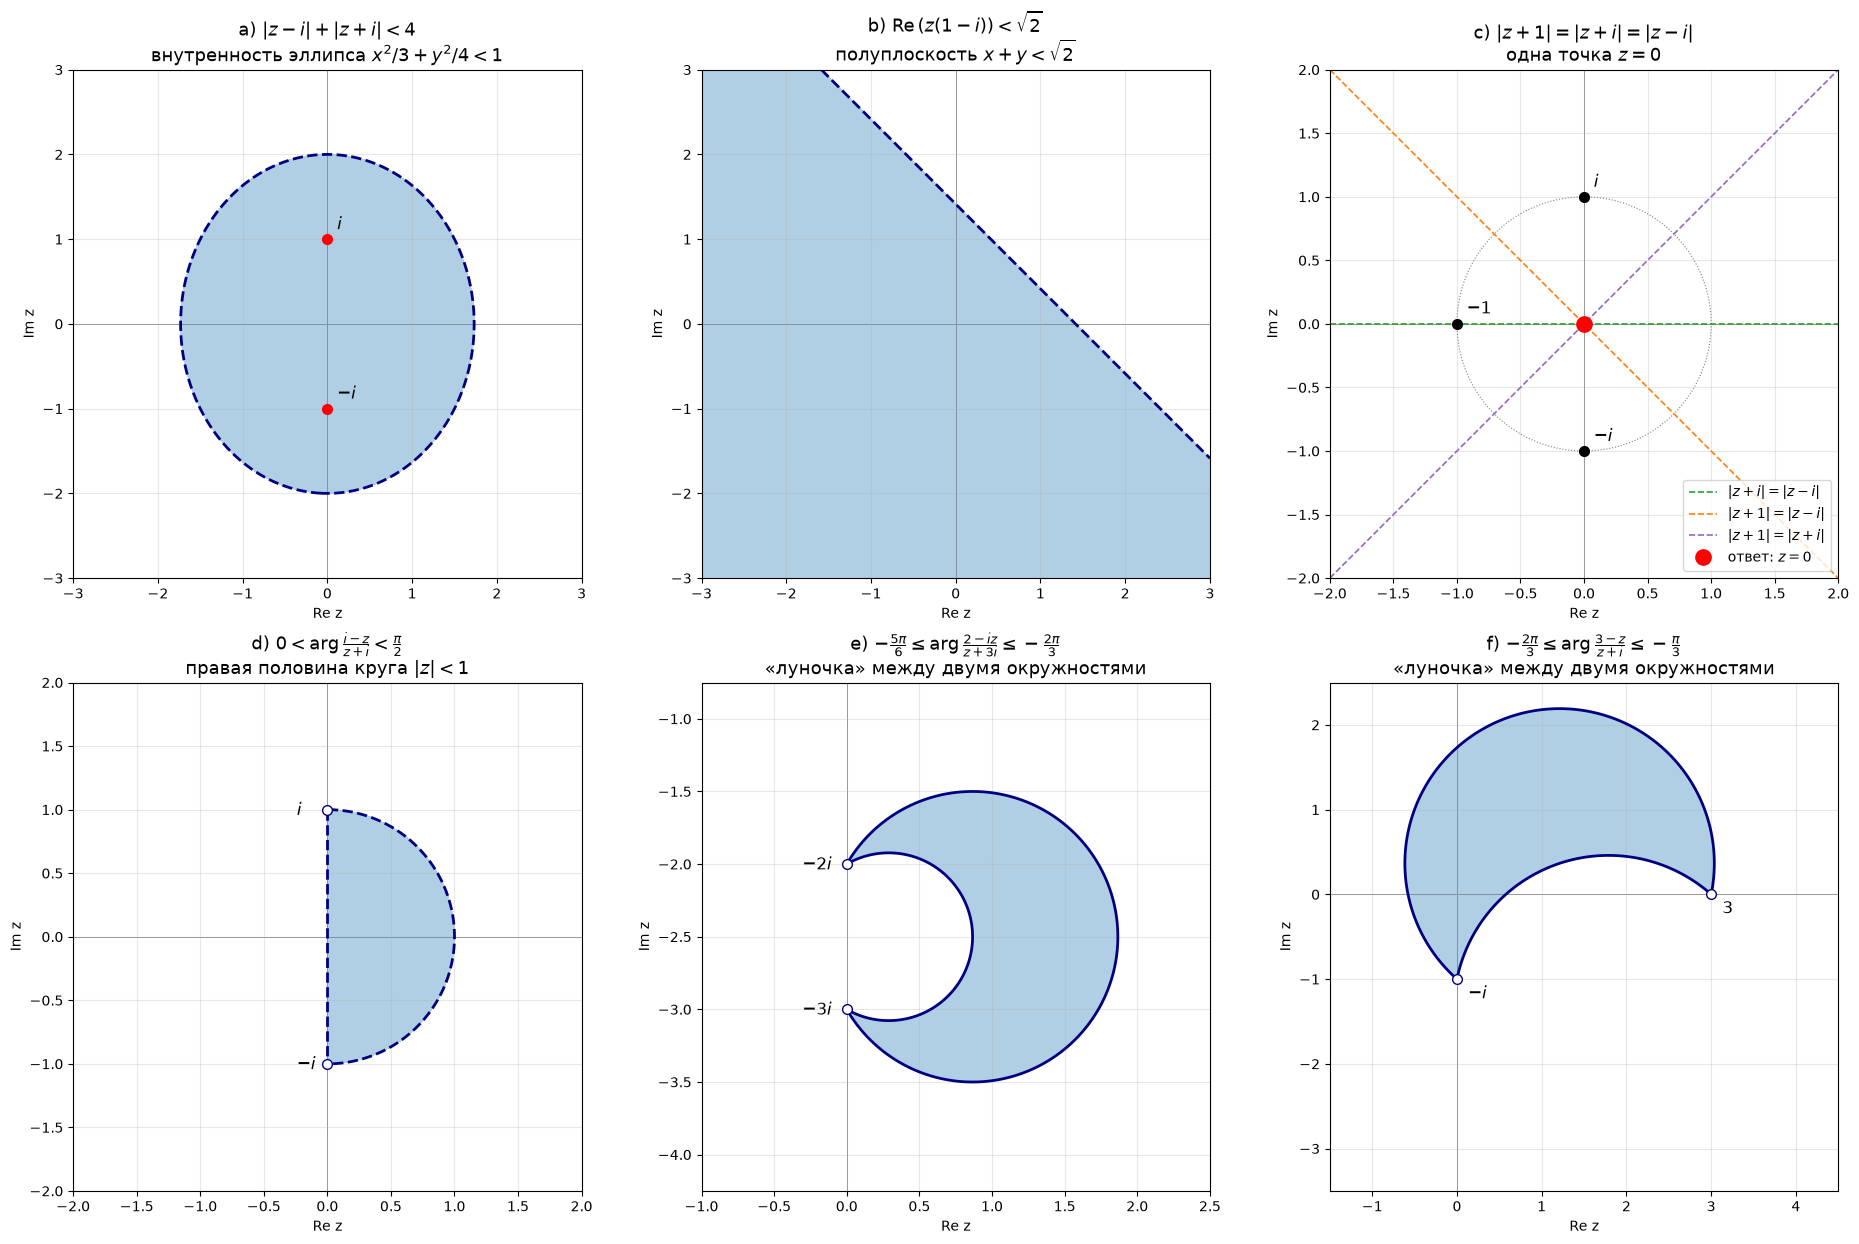

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.seterr(divide='ignore', invalid='ignore')   # в полюсах дробей получается inf/nan — это нормально


def grid(xlim, ylim, n=1001):
    """Сетка точек z = x + iy в прямоугольнике xlim × ylim."""
    X, Y = np.meshgrid(np.linspace(*xlim, n), np.linspace(*ylim, n))
    return X, Y, X + 1j*Y


def fill(ax, X, Y, mask):
    """Закрашивает множество точек, в которых условие (mask) выполнено."""
    ax.contourf(X, Y, mask.astype(float), levels=[0.5, 1.5], colors=['tab:blue'], alpha=0.35)


def arg_line(ax, X, Y, w, theta, style):
    """Линия arg w = theta: Im(w·e^{-iθ}) = 0 при Re(w·e^{-iθ}) > 0."""
    v = w*np.exp(-1j*theta)
    ax.contour(X, Y, np.ma.masked_where(~(v.real > 0), v.imag), levels=[0],
               colors='navy', linestyles=style, linewidths=2)


def points(ax, pts, offset=(7, 7), **kw):
    """Отмечает и подписывает точки комплексной плоскости."""
    for p, name in pts:
        ax.plot(p.real, p.imag, 'o', ms=7, zorder=5, **kw)
        ax.annotate(name, (p.real, p.imag), textcoords="offset points", xytext=offset, fontsize=12)


def finish(ax, title, xlim, ylim):
    ax.axhline(0, color='gray', lw=0.6, zorder=0)
    ax.axvline(0, color='gray', lw=0.6, zorder=0)
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.set_aspect('equal')
    ax.grid(alpha=0.3)
    ax.set_xlabel("Re z")
    ax.set_ylabel("Im z")
    ax.set_title(title, fontsize=13)


fig, axes = plt.subplots(2, 3, figsize=(19, 12.5))
hollow = dict(mfc='white', mec='navy')      # «выколотая» точка
solid = dict(color='red')

# ---------- a) |z - i| + |z + i| < 4: внутренность эллипса с фокусами ±i ----------
ax, xlim, ylim = axes[0, 0], (-3, 3), (-3, 3)
X, Y, Z = grid(xlim, ylim)
F = np.abs(Z - 1j) + np.abs(Z + 1j)
fill(ax, X, Y, F < 4)
ax.contour(X, Y, F, levels=[4], colors='navy', linestyles='--', linewidths=2)   # граница не входит
points(ax, [(1j, "$i$"), (-1j, "$-i$")], **solid)
finish(ax, r"a) $|z-i|+|z+i|<4$" + "\nвнутренность эллипса $x^2/3+y^2/4<1$", xlim, ylim)

# ---------- b) Re(z(1 - i)) < sqrt(2): полуплоскость x + y < sqrt(2) ----------
ax, xlim, ylim = axes[0, 1], (-3, 3), (-3, 3)
X, Y, Z = grid(xlim, ylim)
F = (Z*(1 - 1j)).real
fill(ax, X, Y, F < np.sqrt(2))
ax.contour(X, Y, F, levels=[np.sqrt(2)], colors='navy', linestyles='--', linewidths=2)
finish(ax, r"b) $\mathrm{Re}\,(z(1-i))<\sqrt{2}$" + "\nполуплоскость $x+y<\\sqrt{2}$", xlim, ylim)

# ---------- c) |z + 1| = |z + i| = |z - i|: центр описанной окружности ----------
ax, xlim, ylim = axes[0, 2], (-2, 2), (-2, 2)
p1, p2, p3 = -1 + 0j, -1j, 1j
# |z - p|² = |z - q|²  <=>  2(q - p)·z = |q|² - |p|²  — линейная система относительно (x, y)
M = 2*np.array([[(p2 - p1).real, (p2 - p1).imag],
                [(p3 - p1).real, (p3 - p1).imag]])
rhs = np.array([abs(p2)**2 - abs(p1)**2, abs(p3)**2 - abs(p1)**2])
x0, y0 = np.linalg.solve(M, rhs)
z0 = complex(x0, y0)
print(f"c) единственная точка: z = {z0:.3g},  расстояния до -1, -i, i: "
      f"{abs(z0 - p1):.3f}, {abs(z0 - p2):.3f}, {abs(z0 - p3):.3f}")
t = np.linspace(0, 2*np.pi, 400)
s = np.linspace(-2, 2, 2)
ax.plot(np.cos(t), np.sin(t), color='gray', lw=0.8, ls=':')        # описанная окружность
ax.plot(s, 0*s, color='tab:green', ls='--', lw=1.2, label="$|z+i|=|z-i|$")
ax.plot(s, -s, color='tab:orange', ls='--', lw=1.2, label="$|z+1|=|z-i|$")
ax.plot(s, s, color='tab:purple', ls='--', lw=1.2, label="$|z+1|=|z+i|$")
points(ax, [(p1, "$-1$"), (p2, "$-i$"), (p3, "$i$")], color='black')
ax.plot(x0, y0, 'o', ms=11, color='red', zorder=5, label="ответ: $z=0$")
ax.legend(loc="lower right", fontsize=10)
finish(ax, r"c) $|z+1|=|z+i|=|z-i|$" + "\nодна точка $z=0$", xlim, ylim)

# ---------- d) 0 < arg((i - z)/(z + i)) < pi/2: правая половина единичного круга ----------
ax, xlim, ylim = axes[1, 0], (-2, 2), (-2, 2)
X, Y, Z = grid(xlim, ylim)
W = (1j - Z)/(Z + 1j)
A = np.angle(W)
fill(ax, X, Y, (A > 0) & (A < np.pi/2))
arg_line(ax, X, Y, W, 0, '--')            # arg w = 0  — отрезок мнимой оси
arg_line(ax, X, Y, W, np.pi/2, '--')      # arg w = π/2 — правая полуокружность
points(ax, [(1j, "$i$"), (-1j, "$-i$")], offset=(-22, -4), **hollow)
finish(ax, r"d) $0<\arg\frac{i-z}{z+i}<\frac{\pi}{2}$" + "\nправая половина круга $|z|<1$", xlim, ylim)

# ---------- e) -5pi/6 <= arg((2 - iz)/(z + 3i)) <= -2pi/3 (границы в условии переставлены) ----------
ax, xlim, ylim = axes[1, 1], (-1, 2.5), (-4.25, -0.75)
X, Y, Z = grid(xlim, ylim)
W = (2 - 1j*Z)/(Z + 3j)
A = np.angle(W)
print("e) точек сетки с -2π/3 <= arg w <= -5π/6 (как в условии):",
      int(np.sum((A >= -2*np.pi/3) & (A <= -5*np.pi/6))), "— множество пусто")
fill(ax, X, Y, (A >= -5*np.pi/6) & (A <= -2*np.pi/3))
arg_line(ax, X, Y, W, -5*np.pi/6, '-')    # дуга окружности радиуса 1
arg_line(ax, X, Y, W, -2*np.pi/3, '-')    # дуга окружности радиуса 1/sqrt(3)
points(ax, [(-2j, "$-2i$"), (-3j, "$-3i$")], offset=(-32, -4), **hollow)
finish(ax, r"e) $-\frac{5\pi}{6}\leq\arg\frac{2-iz}{z+3i}\leq-\frac{2\pi}{3}$" + "\n«луночка» между двумя окружностями", xlim, ylim)

# ---------- f) -2pi/3 <= arg((3 - z)/(z + i)) <= -pi/3 ----------
ax, xlim, ylim = axes[1, 2], (-1.5, 4.5), (-3.5, 2.5)
X, Y, Z = grid(xlim, ylim)
W = (3 - Z)/(Z + 1j)
A = np.angle(W)
fill(ax, X, Y, (A >= -2*np.pi/3) & (A <= -np.pi/3))
arg_line(ax, X, Y, W, -2*np.pi/3, '-')
arg_line(ax, X, Y, W, -np.pi/3, '-')
points(ax, [(-1j, "$-i$"), (3 + 0j, "$3$")], offset=(8, -14), **hollow)
finish(ax, r"f) $-\frac{2\pi}{3}\leq\arg\frac{3-z}{z+i}\leq-\frac{\pi}{3}$" + "\n«луночка» между двумя окружностями", xlim, ylim)

plt.tight_layout()
plt.show()